# Shrinkflation in Singapore's private homes
DAO2702 group assignment: the code behind the poster.

Did Singapore's private homes shrink to keep the price tag within reach, and is that still happening in 2025? The notebook answers in three steps that match the poster's rows: what shrank (charts 1 to 3), whether the shrink is real and how it works (4 to 6), and why it happened and what changed (7 to 9).

**Data**
- `properties2025.csv`: URA private home transactions in 2025, the course dataset.
- `properties23.csv`: the same columns for Aug 2020 to Dec 2023, from Lecture 6. It adds the trend.
- `ura_ppi_quarterly.csv`: URA's private residential price index, 1Q2009 = 100, from data.gov.sg.
- `hh_income_change.csv`: SingStat's yearly change in median household employment income, from data.gov.sg.
- Two sets of rules used as inputs. MAS caps loan repayments at 55% of income, tested at 4% interest or more, and lends at most 75% of the price. URA caps how many units a project outside the city centre may build: floor area ÷ 70 m² from 2012, ÷ 85 m² from 2019.

| # | Question | Chart |
|---|---|---|
| 1 | Are 2025 new launches smaller than resale homes? | Back-to-back histogram |
| 2 | When did homes shrink? | Line with interquartile band |
| 3 | Which sizes disappeared? | 100% stacked bar |
| 4 | Is it just location? | Coefficient plot |
| 5 | Did the shrink hold the price tag? | Scatter with constant-price curves |
| 6 | How is a launch priced? | Violin |
| 7 | Why then? Prices against incomes | Diverging lollipop |
| 8 | How much home can a household borrow for? | Sensitivity heat map |
| 9 | What happened once shrinking was capped? | Waterfall |

Run the cells top to bottom. Each chart is saved to `figs/` at the size it has on the poster.

## 0. Setup and cleaning
Both transaction files have the same 12 columns, so they are stacked into one table. Three fixes: "freenhold" in the 2025 file becomes "freehold", the month text becomes a date, and 155 rows with a floor area under 200 or over 5,000 sq ft are dropped. Those are en-bloc sales of whole buildings and penthouses, which would pull the medians around.

A home's vintage is the year its lease started. For a 99-year leasehold that is roughly the year the government sold the land, which is when the developer planned the unit sizes. Freehold homes have no lease-start year, so the vintage charts (2 to 5) use 99-year leaseholds only.

In [1]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import statsmodels.formula.api as smf
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

Path("figs").mkdir(exist_ok=True)

# Palette: blue/orange categorical pair and a blue ordinal ramp, both checked for colour-blind separation
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#8a8984", "#e4e3df"
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#b4b2ab"
RAMP = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]

mpl.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Liberation Sans", "DejaVu Sans"],
        "font.size": 6,
        "text.color": INK,
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK2,
        "axes.linewidth": 0.5,
        "axes.labelsize": 6,
        "axes.titlesize": 6.5,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "xtick.color": INK2,
        "ytick.color": INK2,
        "xtick.labelsize": 5.5,
        "ytick.labelsize": 5.5,
        "xtick.major.width": 0.4,
        "ytick.major.width": 0.4,
        "xtick.major.size": 2,
        "ytick.major.size": 2,
        "grid.color": GRID,
        "grid.linewidth": 0.4,
        "legend.frameon": False,
        "legend.fontsize": 5.5,
        "figure.dpi": 150,
        "savefig.dpi": 600,
        "axes.unicode_minus": True,
    }
)
FIG_W, FIG_H = 2.36, 2.2  # inches, one poster panel

raw25 = pl.read_csv("data/properties2025.csv", infer_schema_length=None)
raw23 = pl.read_csv("data/properties23.csv", infer_schema_length=None)
df = (
    pl.concat([raw23, raw25], how="vertical_relaxed")
    .with_columns(
        tenure=pl.col("tenure").replace(
            "freenhold", "freehold"
        ),  # typo in the 2025 file
        date=pl.col("date").str.to_date("%b-%y"),
    )
    .with_columns(year=pl.col("date").dt.year(), psf=pl.col("price") / pl.col("area"))
    .filter(
        pl.col("area").is_between(200, 5000)
    )  # drops en-bloc and penthouse outliers
)
print(
    f"rows: {raw23.height + raw25.height:,} raw, {df.height:,} kept, {raw23.height + raw25.height - df.height} dropped"
)

# Vintage = lease-start year of 99-year leaseholds, roughly the year the land was sold
ERAS = ["1990–08", "2009–12", "2013–18", "2019–25"]
lease = df.filter(
    (pl.col("tenure") == "99 years") & (pl.col("commence") >= 1990)
).with_columns(era=pl.col("commence").cut([2008, 2012, 2018], labels=ERAS))
d25 = df.filter(pl.col("year") == 2025)
print(
    f"2025 rows: {d25.height:,}; 99-year leasehold rows with a vintage (2020–25): {lease.height:,}"
)
d25.group_by("sale").agg(
    pl.len(),
    pl.col("area").median(),
    pl.col("psf").median().round(0),
    pl.col("price").median(),
).sort("sale")

rows: 98,722 raw, 98,567 kept, 155 dropped
2025 rows: 24,131; 99-year leasehold rows with a vintage (2020–25): 66,237


sale,len,area,psf,price
str,u32,f64,f64,f64
"""New Sale""",10643,796.54,2572.0,2.113059e6
"""Resale""",12549,1011.82,1747.0,1.66e6
"""Sub Sale""",939,764.24,2096.0,1.69e6


## 1. Back-to-back histogram: new launches against resale homes in 2025
New launches sit above the axis and resale homes below it, so the two shapes can be compared without bars hiding each other. Each bar is a 50 sq ft band, as a share of that group's sales. Sub sales (units resold before completion, 4% of 2025) are left out, since they are neither new nor resale.

median new 797 vs resale 1012 sq ft: -21.3%
share >= 1,200 sq ft: new 18%, resale 34%


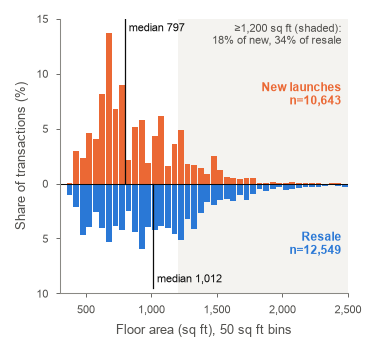

In [2]:
new_a = d25.filter(pl.col("sale") == "New Sale")["area"].to_numpy()
res_a = d25.filter(pl.col("sale") == "Resale")["area"].to_numpy()
med_new, med_res = np.median(new_a), np.median(res_a)
big_new, big_res = (new_a >= 1200).mean(), (res_a >= 1200).mean()
print(
    f"median new {med_new:.0f} vs resale {med_res:.0f} sq ft: {med_new / med_res - 1:+.1%}"
)
print(f"share >= 1,200 sq ft: new {big_new:.0%}, resale {big_res:.0%}")

bins = np.arange(300, 2550, 50)
h_new = np.histogram(new_a, bins)[0] / len(new_a) * 100
h_res = np.histogram(res_a, bins)[0] / len(res_a) * 100
mid = bins[:-1] + 25
fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))
ax.axvspan(1200, 2500, color="#f4f3f0", lw=0, zorder=0)
ax.bar(mid, h_new, width=44, color=ORANGE, lw=0)
ax.bar(mid, -h_res, width=44, color=BLUE, lw=0)
ax.axhline(0, color=INK, lw=0.5)
ax.plot([med_new] * 2, [0, 15], color=INK, lw=0.6)
ax.plot([med_res] * 2, [0, -9.5], color=INK, lw=0.6)
ax.text(med_new + 30, 14.6, f"median {med_new:,.0f}", fontsize=5.4, va="top", color=INK)
ax.text(
    med_res + 30,
    -9.2,
    f"median {med_res:,.0f}",
    fontsize=5.4,
    va="bottom",
    color=INK,
)
ax.text(
    2450,
    7.2,
    f"New launches\nn={len(new_a):,}",
    ha="right",
    fontsize=5.6,
    color=ORANGE,
    fontweight="bold",
)
ax.text(
    2450,
    -6.4,
    f"Resale\nn={len(res_a):,}",
    ha="right",
    fontsize=5.6,
    color=BLUE,
    fontweight="bold",
)
ax.text(
    2450,
    14.6,
    f"≥1,200 sq ft (shaded):\n{big_new:.0%} of new, {big_res:.0%} of resale",
    fontsize=5.2,
    va="top",
    ha="right",
    color=INK2,
)
ax.set_xlim(300, 2500)
ax.set_ylim(-10, 15)
ax.set_xticks([500, 1000, 1500, 2000, 2500])
ax.set_xticklabels(["500", "1,000", "1,500", "2,000", "2,500"])
ax.set_yticks([-10, -5, 0, 5, 10, 15])
ax.set_yticklabels(["10", "5", "0", "5", "10", "15"])
ax.set_xlabel("Floor area (sq ft), 50 sq ft bins")
ax.set_ylabel("Share of transactions (%)")
fig.tight_layout(pad=0.3)
fig.savefig("figs/01_histogram.png")
plt.show()

The median new unit has 797 sq ft against 1,012 for a resale home, 21% smaller. The difference is in the large sizes: homes of 1,200 sq ft or more are 34% of resale sales but only 18% of new launches.

## 2. Line with interquartile band: unit size by lease-start year
Every 2020 to 2025 sale of a 99-year leasehold, grouped by the year its lease started. The line is the median and the band covers the middle half of units, so both the typical home and the spread are visible. Years with fewer than 100 sales are left out.

shape: (30, 5)
┌──────────┬──────┬─────────┬─────────┬─────────┐
│ commence ┆ n    ┆ med     ┆ q25     ┆ q75     │
│ ---      ┆ ---  ┆ ---     ┆ ---     ┆ ---     │
│ f64      ┆ u32  ┆ f64     ┆ f64     ┆ f64     │
╞══════════╪══════╪═════════╪═════════╪═════════╡
│ 1995.0   ┆ 1240 ┆ 1173.28 ┆ 1044.11 ┆ 1302.44 │
│ 1996.0   ┆ 1262 ┆ 1205.57 ┆ 1076.4  ┆ 1280.92 │
│ 1997.0   ┆ 1272 ┆ 1227.1  ┆ 1151.75 ┆ 1388.56 │
│ 1998.0   ┆ 589  ┆ 1216.33 ┆ 1184.04 ┆ 1334.74 │
│ 1999.0   ┆ 304  ┆ 1227.1  ┆ 1108.69 ┆ 1334.74 │
│ …        ┆ …    ┆ …       ┆ …       ┆ …       │
│ 2021.0   ┆ 3904 ┆ 753.48  ┆ 645.84  ┆ 1108.69 │
│ 2022.0   ┆ 2903 ┆ 775.01  ┆ 678.13  ┆ 1087.16 │
│ 2023.0   ┆ 3203 ┆ 764.24  ┆ 667.37  ┆ 1076.4  │
│ 2024.0   ┆ 5634 ┆ 785.77  ┆ 645.84  ┆ 1044.11 │
│ 2025.0   ┆ 781  ┆ 861.12  ┆ 721.19  ┆ 1044.11 │
└──────────┴──────┴─────────┴─────────┴─────────┘
median of 2005–08 vintages 1238 sq ft, 2013–15 vintages 710 sq ft: -43%


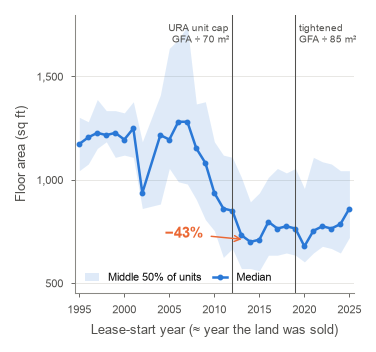

In [3]:
by_year = (
    lease.group_by("commence")
    .agg(
        n=pl.len(),
        med=pl.col("area").median(),
        q25=pl.col("area").quantile(0.25),
        q75=pl.col("area").quantile(0.75),
    )
    .filter((pl.col("n") >= 100) & (pl.col("commence") >= 1995))
    .sort("commence")
)
print(by_year)
peak = by_year.filter(pl.col("commence").is_between(2005, 2008))["med"].median()
trough = by_year.filter(pl.col("commence").is_between(2013, 2015))["med"].median()
print(
    f"median of 2005–08 vintages {peak:.0f} sq ft, 2013–15 vintages {trough:.0f} sq ft: {trough / peak - 1:+.0%}"
)

x = by_year["commence"].to_numpy()
fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))
ax.fill_between(
    x,
    by_year["q25"],
    by_year["q75"],
    color=BLUE,
    alpha=0.15,
    lw=0,
    label="Middle 50% of units",
)
ax.plot(x, by_year["med"], color=BLUE, lw=1.2, marker="o", ms=1.8, label="Median")
ax.axvline(2012, color=INK2, lw=0.5)
ax.axvline(2019, color=INK2, lw=0.5)
ax.text(
    2011.6,
    1760,
    "URA unit cap\nGFA ÷ 70 m²",
    fontsize=5,
    color=INK2,
    va="top",
    ha="right",
)
ax.text(
    2019.4,
    1760,
    "tightened\nGFA ÷ 85 m²",
    fontsize=5,
    color=INK2,
    va="top",
    ha="left",
)
ax.annotate(
    f"{trough / peak - 1:+.0%}".replace("-", "−"),
    xy=(2013.5, trough),
    xytext=(2004.5, 720),
    fontsize=7,
    fontweight="bold",
    color=ORANGE,
    arrowprops=dict(arrowstyle="->", color=ORANGE, lw=0.7),
)
ax.set_xlim(1994.5, 2025.5)
ax.set_ylim(450, 1800)
ax.set_yticks([500, 1000, 1500])
ax.set_yticklabels(["500", "1,000", "1,500"])
ax.set_xlabel("Lease-start year (≈ year the land was sold)")
ax.set_ylabel("Floor area (sq ft)")
ax.legend(loc="lower left", ncol=2, handlelength=1.2, columnspacing=1)
ax.grid(axis="y")
ax.set_axisbelow(True)
fig.tight_layout(pad=0.3)
fig.savefig("figs/02_line_vintage.png")
plt.show()

Sizes held near 1,240 sq ft for land sold up to 2008, then fell to about 710 sq ft for land sold in 2013 to 2015, a drop of 43%. Since then the median has stayed between roughly 680 and 860 sq ft. The fall stopped around URA's 2012 cap on the number of units per project, which was tightened in 2019.

## 3. 100% stacked bar: which sizes disappeared
The same leasehold sales in four lease-start eras and five size bands. Every bar adds up to 100%, so the chart shows the mix and not the number of sales. Shoeboxes (506 sq ft or less, about 47 m²) are orange because they are the size URA's cap was aimed at.

shape: (4, 6)
┌─────────┬──────────────┬───────────┬───────────┬─────────────┬───────────┐
│ era     ┆ ≤506 shoebox ┆ 507–750   ┆ 751–1,000 ┆ 1,001–1,300 ┆ >1,300    │
│ ---     ┆ ---          ┆ ---       ┆ ---       ┆ ---         ┆ ---       │
│ enum    ┆ f64          ┆ f64       ┆ f64       ┆ f64         ┆ f64       │
╞═════════╪══════════════╪═══════════╪═══════════╪═════════════╪═══════════╡
│ 1990–08 ┆ 0.874974     ┆ 4.702987  ┆ 19.2426   ┆ 41.116959   ┆ 34.062479 │
│ 2009–12 ┆ 9.320106     ┆ 22.699554 ┆ 27.969418 ┆ 24.392464   ┆ 15.618458 │
│ 2013–18 ┆ 13.167733    ┆ 35.612445 ┆ 24.859008 ┆ 17.901274   ┆ 8.45954   │
│ 2019–25 ┆ 9.045894     ┆ 38.494364 ┆ 23.204509 ┆ 18.522544   ┆ 10.732689 │
└─────────┴──────────────┴───────────┴───────────┴─────────────┴───────────┘


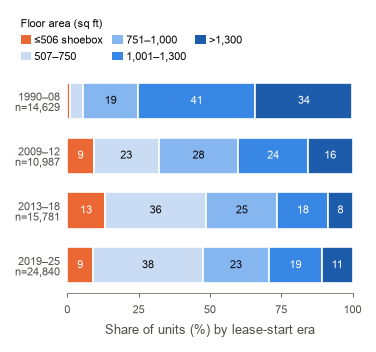

In [4]:
BANDS = ["≤506 shoebox", "507–750", "751–1,000", "1,001–1,300", ">1,300"]
mix = (
    lease.with_columns(band=pl.col("area").cut([506, 750, 1000, 1300], labels=BANDS))
    .group_by("era", "band")
    .len()
    .with_columns(share=pl.col("len") / pl.col("len").sum().over("era") * 100)
    .pivot(on="band", index="era", values="share")
    .sort("era")
    .select("era", *BANDS)
)
print(mix)

band_col = [ORANGE, "#c9dcf3", "#86b6ef", "#3987e5", "#1c5cab"]
era_n = lease.group_by("era").len().sort("era")["len"]
fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))
y = np.arange(len(ERAS))[::-1]
left = np.zeros(len(ERAS))
for band, col in zip(BANDS, band_col):
    w = mix[band].fill_null(0).to_numpy()
    ax.barh(y, w, left=left, color=col, height=0.66, edgecolor="white", lw=0.8)
    for yi, li, wi in zip(y, left, w):
        if wi >= 7:
            ax.text(
                li + wi / 2,
                yi,
                f"{wi:.0f}",
                ha="center",
                va="center",
                fontsize=5.3,
                color="white" if col in ("#3987e5", "#1c5cab", ORANGE) else INK,
            )
    left += w
ax.set_yticks(y)
ax.set_yticklabels(
    [f"{e}\nn={n:,}" for e, n in zip(ERAS, era_n)],
    fontsize=5.3,
    linespacing=1.1,
)
ax.set_xlim(0, 100)
ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xlabel("Share of units (%) by lease-start era")
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.legend(
    handles=[Patch(fc=c, label=b) for b, c in zip(BANDS, band_col)],
    ncol=3,
    loc="lower left",
    bbox_to_anchor=(-0.2, 1.0),
    handlelength=0.9,
    handleheight=0.8,
    columnspacing=0.8,
    handletextpad=0.3,
    title="Floor area (sq ft)",
    title_fontsize=5.3,
    alignment="left",
)
fig.tight_layout(pad=0.3)
fig.savefig("figs/03_stacked_mix.png")
plt.show()

Homes over 1,300 sq ft fell from 34% of units on pre-2009 land to 8% on 2013 to 2018 land, while shoeboxes rose from 1% to 13%. After the 2019 cap shoeboxes dropped back to 9%, but big homes stayed rare at 11%. Most of the growth went to 507 to 750 sq ft, the one and two-bedroom sizes, which went from 5% to 38% of units.

## 4. Coefficient plot: is the shrink just location?
Newer projects could be smaller only because they were built in different districts. To test that, log floor area is regressed on the lease-start era (against 1990 to 2008), first on its own and then with district, property type (apartment or condominium) and year-of-sale effects. Standard errors are clustered by project, because units in one project are designed together and are not independent. The coefficient plot shows both estimates with their 95% confidence intervals side by side.

raw         2009–12: -26.2% [-30.4%, -21.7%]
raw         2013–18: -34.6% [-37.8%, -31.2%]
raw         2019–25: -32.8% [-35.8%, -29.7%]
controlled  2009–12: -25.0% [-29.0%, -20.8%]
controlled  2013–18: -33.9% [-37.3%, -30.3%]
controlled  2019–25: -32.0% [-36.2%, -27.5%]
projects (clusters): 464, R² raw 0.18, controlled 0.22


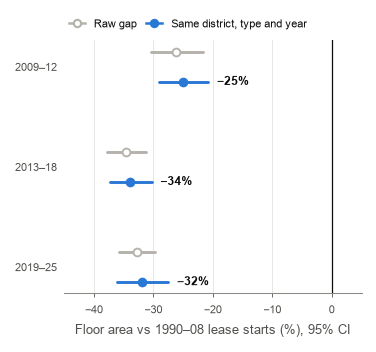

In [5]:
pdf = lease.select("area", "era", "district", "type", "year", "project").to_pandas()
pdf["lna"] = np.log(pdf["area"])
pdf["era"] = pdf["era"].astype(str)
ref = f"C(era, Treatment('{ERAS[0]}'))"
m_raw = smf.ols(f"lna ~ {ref}", data=pdf).fit(
    cov_type="cluster", cov_kwds={"groups": pdf["project"]}
)
m_adj = smf.ols(f"lna ~ {ref} + C(district) + C(type) + C(year)", data=pdf).fit(
    cov_type="cluster", cov_kwds={"groups": pdf["project"]}
)
coef = []
for name, m in [("raw", m_raw), ("controlled", m_adj)]:
    for e in ERAS[1:]:
        k = f"{ref}[T.{e}]"
        lo, hi = m.conf_int().loc[k]
        coef.append((name, e, np.exp(m.params[k]) - 1, np.exp(lo) - 1, np.exp(hi) - 1))
        print(
            f"{name:<11} {e}: {coef[-1][2]:+.1%} [{coef[-1][3]:+.1%}, {coef[-1][4]:+.1%}]"
        )
print(
    f"projects (clusters): {pdf['project'].nunique()}, R² raw {m_raw.rsquared:.2f}, controlled {m_adj.rsquared:.2f}"
)

fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))
for name, e, est, lo, hi in coef:
    raw = name == "raw"
    yy = ERAS[1:].index(e) + (-0.15 if raw else 0.15)
    ax.plot(
        [lo * 100, hi * 100],
        [yy, yy],
        color=GREY if raw else BLUE,
        lw=1.4,
        solid_capstyle="round",
    )
    ax.scatter(
        est * 100,
        yy,
        s=14,
        color="white" if raw else BLUE,
        edgecolor=GREY if raw else BLUE,
        lw=0.9,
        zorder=3,
    )
    if not raw:
        ax.text(
            hi * 100 + 1.5,
            yy,
            f"{est:+.0%}".replace("-", "−"),
            va="center",
            fontsize=5.8,
            fontweight="bold",
            color=INK,
        )
ax.axvline(0, color=INK, lw=0.6)
ax.set_yticks(range(3))
ax.set_yticklabels(ERAS[1:])
ax.invert_yaxis()
ax.set_xlim(-45, 5)
ax.set_xticks([-40, -30, -20, -10, 0])
ax.set_xlabel("Floor area vs 1990–08 lease starts (%), 95% CI")
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.grid(axis="x")
ax.set_axisbelow(True)
ax.legend(
    handles=[
        Line2D(
            [],
            [],
            color=GREY,
            marker="o",
            mfc="white",
            ms=3.5,
            lw=1.2,
            label="Raw gap",
        ),
        Line2D(
            [],
            [],
            color=BLUE,
            marker="o",
            ms=3.5,
            lw=1.2,
            label="Same district, type and year",
        ),
    ],
    loc="lower left",
    bbox_to_anchor=(-0.02, 1.0),
    ncol=2,
    handlelength=1.4,
    columnspacing=0.8,
)
fig.tight_layout(pad=0.3)
fig.savefig("figs/04_coefficients.png")
plt.show()

Adding the controls moves each estimate by about one percentage point. Homes on 2013 to 2018 land are 34% smaller than 1990 to 2008 homes in the same district, of the same type and sold in the same year, so location does not explain the shrink.

## 5. Scatter with constant-price curves: did the shrink hold the price tag?
2025 sales only, so all prices are from the same year. Each dot is one project's median floor area and PSF, and the large markers are the medians of each lease-start era. Both axes are logarithmic, so every point on one grey curve has the same total price. Moving along a curve means trading floor area for PSF at an unchanged price tag.

Older homes are also cheaper per sq ft because of their age and shorter remaining lease. The chart shows what a buyer in 2025 chooses between, not what each home cost when it launched.

shape: (4, 5)
┌─────────┬───────┬─────────┬─────────────┬─────────┐
│ era     ┆ n     ┆ a       ┆ p           ┆ t       │
│ ---     ┆ ---   ┆ ---     ┆ ---         ┆ ---     │
│ enum    ┆ u32   ┆ f64     ┆ f64         ┆ f64     │
╞═════════╪═══════╪═════════╪═════════════╪═════════╡
│ 1990–08 ┆ 2688  ┆ 1216.33 ┆ 1509.66343  ┆ 1.72e6  │
│ 2009–12 ┆ 2109  ┆ 893.41  ┆ 1574.617171 ┆ 1.4e6   │
│ 2013–18 ┆ 3123  ┆ 731.95  ┆ 1922.212701 ┆ 1.45e6  │
│ 2019–25 ┆ 10474 ┆ 785.77  ┆ 2514.267176 ┆ 2.048e6 │
└─────────┴───────┴─────────┴─────────────┴─────────┘
1990–08 → 2013–18: area -40%, PSF +27%, median price -16%
2013–18 → 2019–25: area +7%, PSF +31%, median price +41%


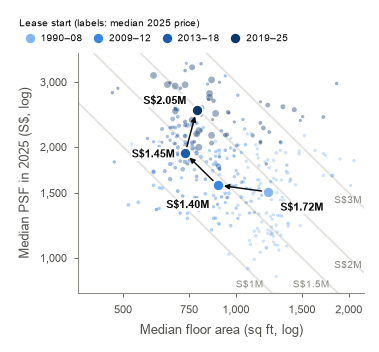

In [6]:
l25 = lease.filter(pl.col("year") == 2025)
proj = (
    l25.group_by("project", "era")
    .agg(n=pl.len(), a=pl.col("area").median(), p=pl.col("psf").median())
    .filter(pl.col("n") >= 10)
)
cent = (
    l25.group_by("era")
    .agg(
        n=pl.len(),
        a=pl.col("area").median(),
        p=pl.col("psf").median(),
        t=pl.col("price").median(),
    )
    .sort("era")
)
print(cent)
c0, c2, c3 = cent.row(0, named=True), cent.row(2, named=True), cent.row(3, named=True)
print(
    f"1990–08 → 2013–18: area {c2['a'] / c0['a'] - 1:+.0%}, PSF {c2['p'] / c0['p'] - 1:+.0%}, median price {c2['t'] / c0['t'] - 1:+.0%}"
)
print(
    f"2013–18 → 2019–25: area {c3['a'] / c2['a'] - 1:+.0%}, PSF {c3['p'] / c2['p'] - 1:+.0%}, median price {c3['t'] / c2['t'] - 1:+.0%}"
)

fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))
xs = np.geomspace(380, 2200, 50)
for T in [1e6, 1.5e6, 2e6, 3e6]:
    ax.plot(xs, T / xs, color=GRID, lw=0.9, zorder=1)
for T, (xl, yl) in {
    1e6: (1180, 820),
    1.5e6: (1770, 820),
    2e6: (2160, 2e6 / 2160),
    3e6: (2160, 3e6 / 2160),
}.items():  # label each curve at the frame edge
    ax.text(
        xl,
        yl,
        f"S${T / 1e6:g}M",
        fontsize=4.8,
        color=MUTED,
        ha="right",
        va="bottom",
    )
for e, col in zip(ERAS, RAMP):
    q = proj.filter(pl.col("era") == e)
    ax.scatter(
        q["a"],
        q["p"],
        s=2 + q["n"].clip(upper_bound=300) / 35,
        color=col,
        alpha=0.4,
        lw=0,
        zorder=2,
    )
ca, cp, ct = cent["a"].to_numpy(), cent["p"].to_numpy(), cent["t"].to_numpy()
for j in range(len(ca) - 1):
    ax.annotate(
        "",
        xy=(ca[j + 1], cp[j + 1]),
        xytext=(ca[j], cp[j]),
        arrowprops=dict(
            arrowstyle="-|>",
            color=INK,
            lw=0.7,
            shrinkA=3,
            shrinkB=3,
            mutation_scale=5,
        ),
        zorder=3,
    )
offsets = [(6, -9), (-4, -11), (-5, -2), (-5, 3)]
aligns = ["left", "right", "right", "right"]
for a_, p_, t_, col, off, ha in zip(ca, cp, ct, RAMP, offsets, aligns):
    ax.scatter(a_, p_, s=28, color=col, edgecolor="white", lw=0.8, zorder=4)
    ax.annotate(
        f"S${t_ / 1e6:.2f}M",
        xy=(a_, p_),
        xytext=off,
        textcoords="offset points",
        ha=ha,
        fontsize=5.3,
        fontweight="bold",
        color=INK,
        bbox=dict(fc="white", ec="none", pad=0.4, alpha=0.85),
        zorder=5,
    )
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(380, 2200)
ax.set_ylim(800, 3600)
ax.set_xticks([500, 750, 1000, 1500, 2000])
ax.set_xticklabels(["500", "750", "1,000", "1,500", "2,000"])
ax.set_yticks([1000, 1500, 2000, 3000])
ax.set_yticklabels(["1,000", "1,500", "2,000", "3,000"])
ax.minorticks_off()
ax.set_xlabel("Median floor area (sq ft, log)")
ax.set_ylabel("Median PSF in 2025 (S$, log)")
ax.legend(
    handles=[
        Line2D([], [], marker="o", ls="", color=c, ms=3.5, label=e)
        for e, c in zip(ERAS, RAMP)
    ],
    ncol=4,
    loc="lower left",
    fontsize=5,
    bbox_to_anchor=(-0.24, 1.0),
    handletextpad=0.05,
    columnspacing=0.5,
    title="Lease start (labels: median 2025 price)",
    title_fontsize=5,
    alignment="left",
)
fig.tight_layout(pad=0.3)
fig.savefig("figs/05_scatter_isoprice.png")
plt.show()

From 1990–2008 land to 2013–2018 land, floor area fell 40% while PSF rose 27%, and the median price fell from S$1.72M to S$1.45M. The smaller size more than paid for the higher PSF. Homes on post-2019 land are 7% larger and 31% dearer per sq ft, and their median price jumps to S$2.05M.

## 6. Violin: how a launch is priced
2025 new sales in projects with at least 20 sales. Each unit's PSF is compared with its own project's median PSF, which takes location out, and units are grouped by size. A violin shows the whole spread in each band. The white dot is the median and the black bar the middle half.

shape: (5, 5)
┌─────────────┬──────┬───────────┬───────────┬──────────┐
│ band        ┆ n    ┆ med       ┆ q25       ┆ q75      │
│ ---         ┆ ---  ┆ ---       ┆ ---       ┆ ---      │
│ enum        ┆ u32  ┆ f64       ┆ f64       ┆ f64      │
╞═════════════╪══════╪═══════════╪═══════════╪══════════╡
│ ≤506        ┆ 662  ┆ -0.453261 ┆ -2.743874 ┆ 1.793077 │
│ 507–750     ┆ 3840 ┆ 0.597899  ┆ -2.586732 ┆ 3.838597 │
│ 751–1,000   ┆ 2501 ┆ 0.157993  ┆ -2.632858 ┆ 3.143144 │
│ 1,001–1,300 ┆ 2312 ┆ -0.281128 ┆ -3.02307  ┆ 2.74027  │
│ >1,300      ┆ 1074 ┆ -1.416917 ┆ -5.079719 ┆ 1.94277  │
└─────────────┴──────┴───────────┴───────────┴──────────┘
within-project elasticity of PSF to floor area: -0.008 (0 = PSF flat across sizes); projects: 50, units: 10,389


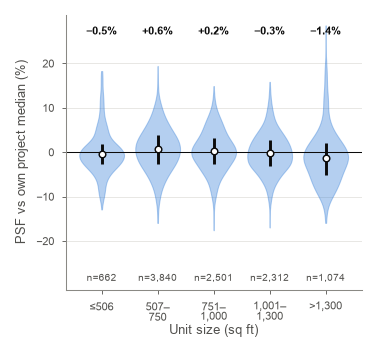

In [7]:
VB = ["≤506", "507–750", "751–1,000", "1,001–1,300", ">1,300"]
launch = (
    d25.filter(pl.col("sale") == "New Sale")
    .filter(pl.len().over("project") >= 20)
    .with_columns(
        dev=(pl.col("psf") / pl.col("psf").median().over("project") - 1) * 100,
        band=pl.col("area").cut([506, 750, 1000, 1300], labels=VB),
    )
)
vstats = (
    launch.group_by("band")
    .agg(
        n=pl.len(),
        med=pl.col("dev").median(),
        q25=pl.col("dev").quantile(0.25),
        q75=pl.col("dev").quantile(0.75),
    )
    .sort("band")
)
print(vstats)
w = launch.select(
    la=pl.col("area").log() - pl.col("area").log().mean().over("project"),
    lp=pl.col("psf").log() - pl.col("psf").log().mean().over("project"),
)
la, lp = w["la"].to_numpy(), w["lp"].to_numpy()
elast = np.cov(la, lp)[0, 1] / la.var(ddof=1)
print(
    f"within-project elasticity of PSF to floor area: {elast:.3f} (0 = PSF flat across sizes); projects: {launch['project'].n_unique()}, units: {launch.height:,}"
)

fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))
data = [launch.filter(pl.col("band") == b)["dev"].clip(-30, 30).to_numpy() for b in VB]
parts = ax.violinplot(
    data,
    positions=range(len(VB)),
    widths=0.8,
    showextrema=False,
    bw_method=0.3,
)
for body in parts["bodies"]:
    body.set_facecolor(BLUE)
    body.set_alpha(0.35)
    body.set_edgecolor(BLUE)
    body.set_linewidth(0.5)
for i, r in enumerate(vstats.iter_rows(named=True)):
    ax.plot([i, i], [r["q25"], r["q75"]], color=INK, lw=1.4, solid_capstyle="butt")
    ax.scatter(i, r["med"], s=10, color="white", edgecolor=INK, lw=0.7, zorder=3)
    ax.text(
        i,
        26.5,
        f"{r['med']:+.1f}%".replace("-", "−"),
        ha="center",
        fontsize=5.4,
        color=INK,
        fontweight="bold",
    )
    ax.text(i, -29, f"n={r['n']:,}", ha="center", fontsize=4.8, color=INK2)
ax.axhline(0, color=INK, lw=0.5)
ax.set_xticks(range(len(VB)))
ax.set_xticklabels(
    ["≤506", "507–\n750", "751–\n1,000", "1,001–\n1,300", ">1,300"],
    fontsize=5.3,
    linespacing=1.0,
)
ax.set_ylim(-31, 31)
ax.set_yticks([-20, -10, 0, 10, 20])
ax.set_xlabel("Unit size (sq ft)", labelpad=1)
ax.set_ylabel("PSF vs own project median (%)")
ax.grid(axis="y")
ax.set_axisbelow(True)
fig.tight_layout(pad=0.3)
fig.savefig("figs/06_violin_pricing.png")
plt.show()

In every size band the median sits within 1.5% of its project's PSF. Inside a launch, a 10% larger unit costs 0.08% less per sq ft, so the price rises almost one for one with floor area. Floor area is the one lever a developer has on the price tag.

## 7. Diverging lollipop: home prices against incomes
This chart uses outside data. The price-to-income ratio divides URA's non-landed price index (yearly average of the quarters) by an index of median household employment income, built by chaining SingStat's yearly changes from 2000 = 100. Income covers resident employed households and includes employer CPF. Each year is shown as its distance from the 2001 to 2025 average, orange above and blue below. Lollipops keep 25 yearly values readable without the visual weight of 25 bars.

shape: (25, 5)
┌──────┬─────────┬────────────┬──────────┬───────────┐
│ year ┆ ppi     ┆ inc        ┆ ratio    ┆ dev       │
│ ---  ┆ ---     ┆ ---        ┆ ---      ┆ ---       │
│ i32  ┆ f64     ┆ f64        ┆ f64      ┆ f64       │
╞══════╪═════════╪════════════╪══════════╪═══════════╡
│ 2001 ┆ 87.45   ┆ 107.3      ┆ 0.815005 ┆ 5.044771  │
│ 2002 ┆ 81.575  ┆ 104.5102   ┆ 0.780546 ┆ 0.603421  │
│ 2003 ┆ 80.15   ┆ 105.032751 ┆ 0.763095 ┆ -1.64575  │
│ 2004 ┆ 79.975  ┆ 103.667325 ┆ 0.771458 ┆ -0.56788  │
│ 2005 ┆ 82.7    ┆ 110.094699 ┆ 0.751171 ┆ -3.182594 │
│ …    ┆ …       ┆ …          ┆ …        ┆ …         │
│ 2021 ┆ 161.05  ┆ 216.670269 ┆ 0.743295 ┆ -4.197741 │
│ 2022 ┆ 176.375 ┆ 229.670486 ┆ 0.767948 ┆ -1.020289 │
│ 2023 ┆ 189.125 ┆ 246.895772 ┆ 0.766011 ┆ -1.269887 │
│ 2024 ┆ 198.575 ┆ 256.771603 ┆ 0.773353 ┆ -0.323696 │
│ 2025 ┆ 207.2   ┆ 272.948214 ┆ 0.759118 ┆ -2.158334 │
└──────┴─────────┴────────────┴──────────┴───────────┘
least affordable years: [2007, 2010, 2008, 2011, 2

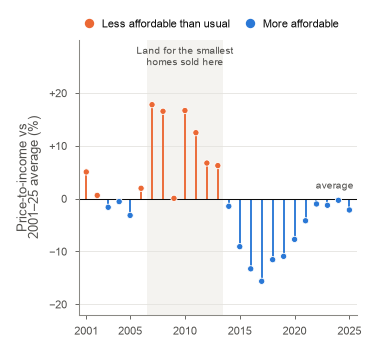

In [8]:
ppi = (
    pl.read_csv("data/ura_ppi_quarterly.csv")
    .filter(pl.col("property_type") == "Non-Landed")
    .with_columns(year=pl.col("quarter").str.slice(0, 4).cast(pl.Int32))
    .group_by("year")
    .agg(ppi=pl.col("index").mean())
    .sort("year")
)
inc = (
    pl.read_csv("data/hh_income_change.csv", infer_schema_length=None)
    .filter(pl.col("PerCent").str.contains(r"^\d{4}$"))
    .select(
        year=pl.col("PerCent").cast(pl.Int32),
        g=pl.col("NominalChangeinIncome_ResidentEmployedHouseholds_Median2").cast(
            pl.Float64
        ),
    )
    .sort("year")
    .with_columns(
        inc=100 * (1 + pl.col("g") / 100).cum_prod()
    )  # chained index, 2000 = 100
)
macro = (
    ppi.join(inc.select("year", "inc"), on="year", how="inner")
    .sort("year")
    .with_columns(ratio=pl.col("ppi") / pl.col("inc"))
    .with_columns(dev=(pl.col("ratio") / pl.col("ratio").mean() - 1) * 100)
)
print(macro)
print(
    f"least affordable years: {macro.sort('dev', descending=True).head(5)['year'].to_list()}; 2025 vs average {macro['dev'][-1]:+.1f}%"
)

fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))
ax.axvspan(2006.5, 2013.5, color="#f4f3f0", lw=0, zorder=0)
ax.text(
    2010,
    29,
    "Land for the smallest\nhomes sold here",
    ha="center",
    va="top",
    fontsize=5,
    color=INK2,
)
yrs, dev = macro["year"].to_numpy(), macro["dev"].to_numpy()
cols = np.where(dev > 0, ORANGE, BLUE)
ax.vlines(yrs, 0, dev, color=cols, lw=0.9)
ax.scatter(yrs, dev, s=9, color=cols, edgecolor="white", lw=0.4, zorder=3)
ax.axhline(0, color=INK, lw=0.5)
ax.text(2025.4, 1.5, "average", fontsize=4.8, color=INK2, ha="right", va="bottom")
ax.set_xlim(2000.3, 2025.7)
ax.set_ylim(-22, 30)
ax.set_xticks([2001, 2005, 2010, 2015, 2020, 2025])
ax.set_yticks([-20, -10, 0, 10, 20])
ax.set_yticklabels(["−20", "−10", "0", "+10", "+20"])
ax.set_ylabel("Price-to-income vs\n2001–25 average (%)", linespacing=1.1)
ax.legend(
    handles=[
        Line2D(
            [],
            [],
            marker="o",
            ls="",
            color=ORANGE,
            ms=3.5,
            label="Less affordable than usual",
        ),
        Line2D([], [], marker="o", ls="", color=BLUE, ms=3.5, label="More affordable"),
    ],
    ncol=2,
    loc="lower left",
    bbox_to_anchor=(-0.04, 1.0),
    handletextpad=0.1,
    columnspacing=0.8,
)
ax.grid(axis="y")
ax.set_axisbelow(True)
fig.tight_layout(pad=0.3)
fig.savefig("figs/07_lollipop_macro.png")
plt.show()

Homes were 6 to 18% less affordable than usual in every year from 2007 to 2013 except 2009, which is when the land behind the smallest homes in chart 2 was sold. Incomes then grew faster than prices, and by 2025 the ratio is back near its average, 2% below.

## 8. Sensitivity heat map: how much home a household can borrow for
MAS limits a home loan so that repayments are at most 55% of gross monthly income (the TDSR), worked out at the actual loan rate or 4%, whichever is higher, over 30 years. Banks lend at most 75% of the price, so the most a household can pay is the loan divided by 0.75. Dividing that by PSF gives the largest floor area it can afford. The heat map runs this for six incomes and seven PSF levels to show how the answer moves with each. Cash or CPF beyond the 25% down payment is ignored.

price ceiling at median income: S$1,911,767; new-launch median PSF 2020 1,712, 2025 2,572
affordable area at median income: 2020 PSF 1,117 sq ft, 2025 PSF 743 sq ft (-33%)
2025 new-launch median size 797 sq ft


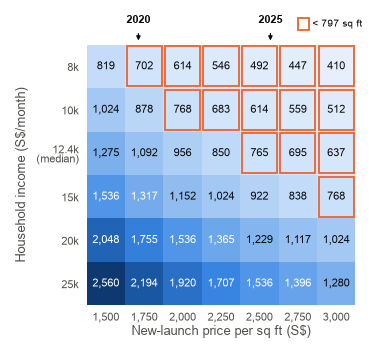

In [9]:
TDSR, LTV, STRESS, MONTHS = 0.55, 0.75, 0.04, 360
annuity = (1 - (1 + STRESS / 12) ** -MONTHS) / (STRESS / 12)
INCOMES = [
    8000,
    10000,
    12446,
    15000,
    20000,
    25000,
]  # 12,446 = 2025 median household income (SingStat KHIT 2025)
PSFS = [1500, 1750, 2000, 2250, 2500, 2750, 3000]
grid = np.array([[TDSR * i * annuity / LTV / p for p in PSFS] for i in INCOMES])
new20 = df.filter((pl.col("year") == 2020) & (pl.col("sale") == "New Sale"))[
    "psf"
].median()
new25 = d25.filter(pl.col("sale") == "New Sale")["psf"].median()
cap_med = TDSR * 12446 * annuity / LTV
print(
    f"price ceiling at median income: S${cap_med:,.0f}; new-launch median PSF 2020 {new20:,.0f}, 2025 {new25:,.0f}"
)
print(
    f"affordable area at median income: 2020 PSF {cap_med / new20:,.0f} sq ft, 2025 PSF {cap_med / new25:,.0f} sq ft ({new20 / new25 - 1:+.0%})"
)
print(f"2025 new-launch median size {med_new:.0f} sq ft")

cmap = LinearSegmentedColormap.from_list(
    "blue", ["#eef4fc", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
)
fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))
ax.imshow(grid, cmap=cmap, aspect="auto", vmin=300, vmax=2600)
for i in range(len(INCOMES)):
    for j in range(len(PSFS)):
        v = grid[i, j]
        ax.text(
            j,
            i,
            f"{v:,.0f}",
            ha="center",
            va="center",
            fontsize=5.2,
            color="white" if v > 1300 else INK,
        )
        if v < med_new:  # cannot reach the 2025 median new-launch size
            ax.add_patch(
                plt.Rectangle(
                    (j - 0.46, i - 0.46),
                    0.92,
                    0.92,
                    fill=False,
                    ec=ORANGE,
                    lw=0.9,
                    zorder=4,
                )
            )
ax.set_xticks(range(len(PSFS)))
ax.set_xticklabels([f"{p:,}" for p in PSFS], fontsize=5.2)
ax.set_yticks(range(len(INCOMES)))
ax.set_yticklabels(
    [f"{i / 1000:g}k" if i != 12446 else "12.4k\n(median)" for i in INCOMES],
    fontsize=5.2,
    linespacing=1.0,
)
ax.set_xlabel("New-launch price per sq ft (S$)", labelpad=1)
ax.set_ylabel("Household income (S$/month)")
for p, lab in [(new20, "2020"), (new25, "2025")]:
    xpos = np.interp(p, PSFS, range(len(PSFS)))
    ax.annotate(
        lab,
        xy=(xpos, -0.5),
        xytext=(xpos, -1.0),
        ha="center",
        fontsize=5.3,
        color=INK,
        fontweight="bold",
        annotation_clip=False,
        arrowprops=dict(arrowstyle="-|>", color=INK, lw=0.6, mutation_scale=4),
    )
ax.add_patch(
    plt.Rectangle(
        (5.0, -1.12),
        0.28,
        0.28,
        fill=False,
        ec=ORANGE,
        lw=0.9,
        clip_on=False,
    )
)
ax.text(
    5.38,
    -0.98,
    f"< {med_new:,.0f} sq ft",
    fontsize=5,
    va="center",
    color=INK,
    clip_on=False,
)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
fig.tight_layout(pad=0.3)
fig.savefig("figs/08_heatmap_tdsr.png")
plt.show()

At the 2025 median household income of S$12,446, the limit is a S$1.91M home. At the 2020 new-launch PSF that bought 1,117 sq ft. At the 2025 PSF it buys 743 sq ft, less than the median new unit of 797 sq ft. Because banks must test at 4% or more, rate cuts below 4% do not change any cell in the table.

## 9. Waterfall: what happened once shrinking was capped
New sales in Aug to Dec 2020, the first months in the Lecture 6 file, against 2025. With geometric means, ln(price) = ln(PSF) + ln(floor area), so the price change splits exactly into a PSF part and a floor-area part. Each of URA's three regions (core central CCR, rest of central RCR, outside central OCR) is compared with itself and weighted by its 2025 sales, so a shift in where launches happen does not count as a price change. The waterfall shows how the two parts stack from the 2020 price to the 2025 price.

shape: (3, 10)
┌─────────┬────────┬────────┬───────────┬───┬───────────┬──────────┬──────────┬──────────┐
│ segment ┆ n_2020 ┆ n_2025 ┆ lp_2020   ┆ … ┆ lpsf_2025 ┆ la_2020  ┆ la_2025  ┆ w        │
│ ---     ┆ ---    ┆ ---    ┆ ---       ┆   ┆ ---       ┆ ---      ┆ ---      ┆ ---      │
│ str     ┆ u32    ┆ u32    ┆ f64       ┆   ┆ f64       ┆ f64      ┆ f64      ┆ f64      │
╞═════════╪════════╪════════╪═══════════╪═══╪═══════════╪══════════╪══════════╪══════════╡
│ CCR     ┆ 360    ┆ 1906   ┆ 14.522907 ┆ … ┆ 8.029005  ┆ 6.646029 ┆ 6.660088 ┆ 0.179085 │
│ OCR     ┆ 2244   ┆ 4337   ┆ 14.067505 ┆ … ┆ 7.720981  ┆ 6.704589 ┆ 6.754784 ┆ 0.407498 │
│ RCR     ┆ 2308   ┆ 4400   ┆ 14.181049 ┆ … ┆ 7.92267   ┆ 6.641358 ┆ 6.751918 ┆ 0.413417 │
└─────────┴────────┴────────┴───────────┴───┴───────────┴──────────┴──────────┴──────────┘
typical new-launch price 2020 S$1,463,003 → 2025 S$2,182,902 (+49%)
from PSF +39.3% (S$+575,010); from floor area +7.1% (S$+144,889)


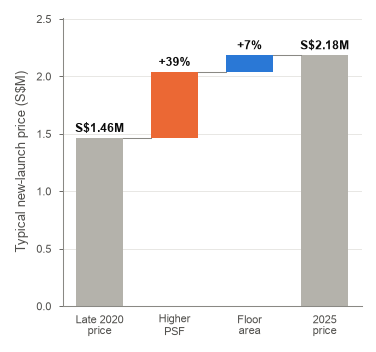

In [10]:
seg = (
    df.filter(pl.col("sale") == "New Sale", pl.col("year").is_in([2020, 2025]))
    .group_by("segment", "year")
    .agg(
        n=pl.len(),
        lp=pl.col("price").log().mean(),
        lpsf=pl.col("psf").log().mean(),
        la=pl.col("area").log().mean(),
    )
    .sort("segment", "year")
)
wide = seg.pivot(on="year", index="segment", values=["n", "lp", "lpsf", "la"])
wide = wide.with_columns(w=pl.col("n_2025") / pl.col("n_2025").sum())
d_psf = (wide["w"] * (wide["lpsf_2025"] - wide["lpsf_2020"])).sum()
d_area = (wide["w"] * (wide["la_2025"] - wide["la_2020"])).sum()
p0 = np.exp((wide["w"] * wide["lp_2020"]).sum())
p1 = p0 * np.exp(d_psf + d_area)
step_psf = p0 * np.exp(d_psf) - p0
step_area = p1 - p0 * np.exp(d_psf)
print(wide)
print(
    f"typical new-launch price 2020 S${p0:,.0f} → 2025 S${p1:,.0f} ({p1 / p0 - 1:+.0%})"
)
print(
    f"from PSF {np.exp(d_psf) - 1:+.1%} (S${step_psf:+,.0f}); from floor area {np.exp(d_area) - 1:+.1%} (S${step_area:+,.0f})"
)

fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))
levels = [p0, p0 + step_psf, p1]
ax.bar(0, p0 / 1e6, color=GREY, width=0.62)
ax.bar(1, step_psf / 1e6, bottom=p0 / 1e6, color=ORANGE, width=0.62)
ax.bar(2, step_area / 1e6, bottom=(p0 + step_psf) / 1e6, color=BLUE, width=0.62)
ax.bar(3, p1 / 1e6, color=GREY, width=0.62)
for k, (top, txt) in enumerate(
    [
        (p0, f"S${p0 / 1e6:.2f}M"),
        (p0 + step_psf, f"{np.exp(d_psf) - 1:+.0%}"),
        (max(levels[1], p1), f"{np.exp(d_area) - 1:+.0%}"),
        (p1, f"S${p1 / 1e6:.2f}M"),
    ]
):
    ax.text(
        k,
        top / 1e6 + 0.03,
        txt.replace("-", "−"),
        ha="center",
        va="bottom",
        fontsize=5.8,
        fontweight="bold",
        color=INK,
    )
for k in range(3):
    ax.plot([k + 0.31, k + 0.69], [levels[k] / 1e6] * 2, color=MUTED, lw=0.5)
ax.set_xticks(range(4))
ax.set_xticklabels(
    ["Late 2020\nprice", "Higher\nPSF", "Floor\narea", "2025\nprice"],
    fontsize=5.5,
    linespacing=1.1,
)
ax.set_ylim(0, p1 / 1e6 * 1.15)
ax.set_ylabel("Typical new-launch price (S$M)")
ax.tick_params(axis="x", length=0)
ax.grid(axis="y")
ax.set_axisbelow(True)
fig.tight_layout(pad=0.3)
fig.savefig("figs/09_waterfall.png")
plt.show()

The typical new-launch price rose 49%, from S$1.46M to S$2.18M. PSF added 39% and floor area 7%. Units grew a little instead of shrinking, so buyers now carry the whole PSF rise.

## 10. Counts used on the poster

In [11]:
print(
    f"2025 rows {raw25.height:,}; kept {d25.height:,}; new {len(new_a):,}, resale {len(res_a):,}, sub sale {d25.filter(pl.col('sale') == 'Sub Sale').height}"
)
print(
    f"2020–23 rows {raw23.height:,}; kept {df.filter(pl.col('year') < 2025).height:,}"
)
print(
    f"new vs resale median area: {med_new:.0f} vs {med_res:.0f} ({med_new / med_res - 1:+.1%}); PSF {new25:,.0f} vs {d25.filter(pl.col('sale') == 'Resale')['psf'].median():,.0f}"
)

2025 rows 24,151; kept 24,131; new 10,643, resale 12,549, sub sale 939
2020–23 rows 74,571; kept 74,436
new vs resale median area: 797 vs 1012 (-21.3%); PSF 2,572 vs 1,747


## Conclusion
Yes, Singapore's private homes shrank to keep the price tag within reach, and URA's unit cap has stopped it. Homes on land sold from 2009 to 2013, when prices ran furthest ahead of incomes, are about 40% smaller than older homes, by the same margin within each district. Because a launch is priced per sq ft, a smaller unit was the only way to hold the price tag down, and in 2025 prices those homes still cost less than older, bigger ones. Since the 2019 cap the shrink has stopped, and the new-launch price tag rose 49% from late 2020 to 2025, close to what a median household can borrow.

Limitations: the eras are compared at 2025 prices, not at their launch prices, and older homes also lose value with age and a shorter lease. The data has no bedroom count, 2024 is missing, and the income series includes employer CPF, so real borrowing power is a little lower than in chart 8. All results are associations, not causal effects.

## References
1. URA REALIS private residential transactions, 2025 (`properties2025.csv`, course dataset) and Aug 2020 to Dec 2023 (`properties23.csv`, Lecture 6).
2. URA, Private Residential Property Price Index (1Q2009 = 100), quarterly. data.gov.sg dataset d_97f8a2e995022d311c6c68cfda6d034c.
3. SingStat, change in median monthly household employment income, 2000 to 2025. data.gov.sg dataset d_968496622a54acf5f67256434453b94c. Median household income of S$12,446 from Key Household Income Trends 2025 (press release, 9 Feb 2026).
4. MAS, TDSR of 55% (from 16 Dec 2021) and 4% medium-term interest rate floor (from 30 Sep 2022). Summary: https://www.dbs.com.sg/personal/articles/nav/budget-spend/what-to-know-about-TDSR
5. URA circular DC18-06 (17 Oct 2018): maximum dwelling units outside the Central Area = GFA / 85 m² from 17 Jan 2019, replacing GFA / 70 m² (from Jan 2012). https://www.ura.gov.sg/guidelines/archived-circulars/dc18-06/
6. ONS (2019), "The impact of shrinkflation on CPIH, UK". https://www.ons.gov.uk/economy/inflationandpriceindices/articles/theimpactofshrinkflationoncpihuk/howmanyofourproductsaregettingsmaller